# Magnitude Ablation — Are Big Coupling Changes More Predictable?

**Why:** Our 73% directional accuracy is averaged over all 9,025 cells, but most
are near-frozen (tiny noise-level changes). The 73% is dominated by predicting
noise we can't predict. The sparse-event reframe says: ignore the frozen majority,
predict only the few pairs about to *meaningfully shift*.

**This notebook tests the bet** (no training): does directional predictability
*rise* as the change magnitude grows?
- If YES -> big moves carry structure -> build sparse Trial 8.
- If NO  -> big moves are noise too -> sparse won't help, pivot elsewhere.

**Predictors tested** (simple rules, no learning) for sign of future change
`future_delta = corr[t+H] - corr[t]`:
- momentum         : sign(recent_delta)
- delta mean-rev   : -sign(recent_delta)
- level mean-rev   : -sign(corr[t] - trailing_mean)   (high now -> expect fall)

We also check: how sparse are big moves, do they revert, and do events concentrate
on specific pairs (learnable structure in *where* events happen).

In [1]:
# Cell 1 - Load & setup
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_cwd = os.getcwd()
PROJECT_DIR = os.path.abspath(os.path.join(_cwd, '..')) if os.path.basename(_cwd)=='notebooks' else _cwd
DATA = os.path.join(PROJECT_DIR, 'data', 'processed')
PLOTS = os.path.join(PROJECT_DIR, 'outputs', 'plots')

corr = np.load(os.path.join(DATA, 'corr_video.npy'))      # (T, 95, 95), return-corr
with open(os.path.join(DATA, 'video_meta.pkl'), 'rb') as f:
    vm = pickle.load(f)
ordered_tickers = vm['ordered_tickers']   # Fiedler order (matches corr layout)

T, N, _ = corr.shape
HORIZON = 5
REF_WIN = 20      # trailing window for the 'level mean-reversion' reference
print(f'corr_video {corr.shape}  H={HORIZON}  ref_win={REF_WIN}')

# Upper-triangle indices (unique pairs only, exclude diagonal)
iu, ju = np.triu_indices(N, k=1)
N_PAIRS = len(iu)
print(f'unique pairs = {N_PAIRS}')


corr_video (1157, 95, 95)  H=5  ref_win=20
unique pairs = 4465


In [2]:
# Cell 2 - Build per-cell arrays: future change, recent change, level deviation

# Causal trailing mean of each cell over REF_WIN snapshots (reference 'normal' level)
csum = np.cumsum(corr, axis=0)
trailing_mean = np.full_like(corr, np.nan)
for t in range(REF_WIN, T):
    trailing_mean[t] = (csum[t-1] - csum[t-1-REF_WIN]) / REF_WIN

# Valid snapshots: need t-1 (recent), t-REF_WIN (trailing), t+H (future)
t_lo, t_hi = REF_WIN, T - HORIZON
ts = np.arange(t_lo, t_hi)
print(f'valid snapshots: {len(ts)}  ({t_lo}..{t_hi-1})')

# Flatten to (n_t, N_PAIRS) on unique pairs
def up(a):  # take upper-triangle of each (.,N,N) frame -> (.,N_PAIRS)
    return a[:, iu, ju]

future_delta = up(corr[ts + HORIZON] - corr[ts])      # what we want to predict the sign of
recent_delta = up(corr[ts] - corr[ts - 1])
level_dev    = up(corr[ts] - trailing_mean[ts])       # current vs its own recent normal

print('future_delta: mean|.|=%.4f  std=%.4f' % (np.abs(future_delta).mean(), future_delta.std()))
print('shapes:', future_delta.shape)


valid snapshots: 1132  (20..1151)
future_delta: mean|.|=0.2811  std=0.3639
shapes: (1132, 4465)


In [3]:
# Cell 3 - How sparse are big moves? Event base-rate at thresholds

absd = np.abs(future_delta).reshape(-1)
print('Distribution of |future_delta| (H=%d):' % HORIZON)
for p in [50, 75, 90, 95, 99]:
    print(f'  {p}th pct: {np.percentile(absd, p):.4f}')
print()
print(f'{"tau":>6} {"event_rate":>12} {"n_events":>12}')
print('-'*32)
THRESHOLDS = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30]
for tau in THRESHOLDS:
    rate = float((absd > tau).mean())
    print(f'{tau:>6.2f} {rate*100:>11.1f}% {int((absd>tau).sum()):>12,}')
print('\n(sparse formulation needs a tau where events are a small but learnable minority, ~5-15%)')


Distribution of |future_delta| (H=5):
  50th pct: 0.2257
  75th pct: 0.3964
  90th pct: 0.5951
  95th pct: 0.7372
  99th pct: 1.0399

   tau   event_rate     n_events
--------------------------------
  0.00       100.0%    5,054,379
  0.02        95.2%    4,809,548
  0.05        87.9%    4,444,316
  0.10        76.2%    3,851,549
  0.15        65.1%    3,291,752
  0.20        54.9%    2,773,739
  0.30        37.5%    1,895,893

(sparse formulation needs a tau where events are a small but learnable minority, ~5-15%)


In [4]:
# Cell 4 - THE KEY TEST: directional predictability vs change magnitude

# Predictors of sign(future_delta)
pred_mom    = np.sign(recent_delta)        # momentum
pred_dmr    = -np.sign(recent_delta)       # delta mean-reversion
pred_lmr    = -np.sign(level_dev)          # level mean-reversion
truth       = np.sign(future_delta)

fd = future_delta.reshape(-1)
absd = np.abs(fd)
t_ = truth.reshape(-1)
preds = {'momentum': pred_mom.reshape(-1),
         'delta_meanrev': pred_dmr.reshape(-1),
         'level_meanrev': pred_lmr.reshape(-1)}

print(f'Directional accuracy on cells with |future_delta| > tau:')
print(f'{"tau":>6} {"n":>10} {"momentum":>10} {"delta_MR":>10} {"level_MR":>10} {"best":>8}')
print('-'*60)
rows=[]
for tau in THRESHOLDS:
    mask = absd > tau
    nz = mask & (t_ != 0)
    n = int(nz.sum())
    accs = {}
    for name, p in preds.items():
        pm = p.reshape(-1)[nz]
        valid = pm != 0
        accs[name] = float((pm[valid]==t_[nz][valid]).mean()) if valid.sum()>0 else np.nan
    best = max(accs.values())
    rows.append(dict(tau=tau, n=n, **accs, best=best))
    print(f'{tau:>6.2f} {n:>10,} {accs["momentum"]:>10.4f} {accs["delta_meanrev"]:>10.4f} '
          f'{accs["level_meanrev"]:>10.4f} {best:>8.4f}')
mag_df = pd.DataFrame(rows)
print('\nKEY: if "best" RISES with tau -> big moves more predictable -> sparse wins.')


Directional accuracy on cells with |future_delta| > tau:
   tau          n   momentum   delta_MR   level_MR     best
------------------------------------------------------------
  0.00  5,054,379     0.3424     0.6576     0.7339   0.7339
  0.02  4,809,548     0.3348     0.6652     0.7452   0.7452
  0.05  4,444,316     0.3232     0.6768     0.7623   0.7623
  0.10  3,851,549     0.3037     0.6963     0.7900   0.7900
  0.15  3,291,752     0.2847     0.7153     0.8162   0.8162
  0.20  2,773,739     0.2661     0.7339     0.8410   0.8410
  0.30  1,895,893     0.2310     0.7690     0.8839   0.8839

KEY: if "best" RISES with tau -> big moves more predictable -> sparse wins.


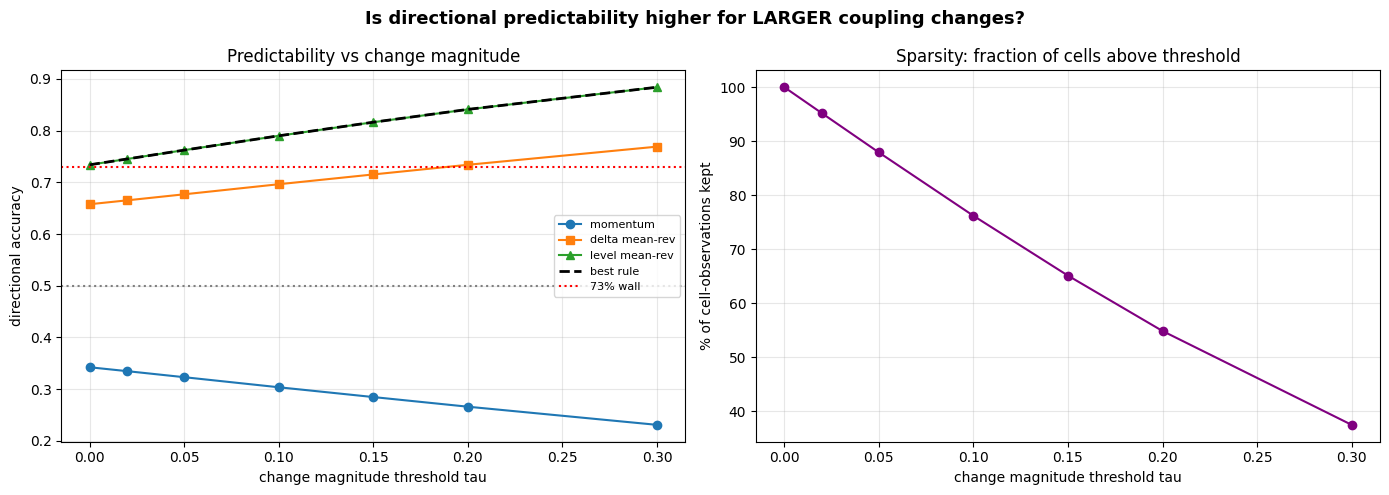

Saved magnitude_ablation.png


In [5]:
# Cell 5 - Plot predictability vs magnitude + the verdict curve

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Is directional predictability higher for LARGER coupling changes?',
             fontsize=13, fontweight='bold')

ax[0].plot(mag_df['tau'], mag_df['momentum'],      'o-', label='momentum')
ax[0].plot(mag_df['tau'], mag_df['delta_meanrev'], 's-', label='delta mean-rev')
ax[0].plot(mag_df['tau'], mag_df['level_meanrev'], '^-', label='level mean-rev')
ax[0].plot(mag_df['tau'], mag_df['best'], 'k--', lw=2, label='best rule')
ax[0].axhline(0.5, color='grey', ls=':'); ax[0].axhline(0.73, color='red', ls=':', label='73% wall')
ax[0].set_xlabel('change magnitude threshold tau'); ax[0].set_ylabel('directional accuracy')
ax[0].set_title('Predictability vs change magnitude'); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

# event rate (right axis context)
ax[1].plot(mag_df['tau'], mag_df['n']/ (len(future_delta.reshape(-1))) * 100, 'o-', color='purple')
ax[1].set_xlabel('change magnitude threshold tau'); ax[1].set_ylabel('% of cell-observations kept')
ax[1].set_title('Sparsity: fraction of cells above threshold'); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS, 'magnitude_ablation.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved magnitude_ablation.png')


Event threshold tau=0.15, overall event rate=65.1%
Per-pair event rate: min=39.8%  median=65.2%  max=72.1%
Top 10% most event-prone pairs account for 10.5% of all events.
Event-proneness persistence (corr of per-pair rate, 1st vs 2nd half): +0.213
  (high -> the SAME pairs stay event-prone -> learnable structure in where events occur)

Most event-prone pairs:
    ASIANPAINT <-> INFY          event rate 72.1%
          INFY <-> ADANIGREEN    event rate 71.9%
          ONGC <-> ASIANPAINT    event rate 71.8%
      HINDALCO <-> ADANIGREEN    event rate 71.3%
           TCS <-> HDFCBANK      event rate 71.1%
          INFY <-> POWERGRID     event rate 70.9%
          INFY <-> ICICIBANK     event rate 70.8%
      HINDALCO <-> CGPOWER       event rate 70.8%


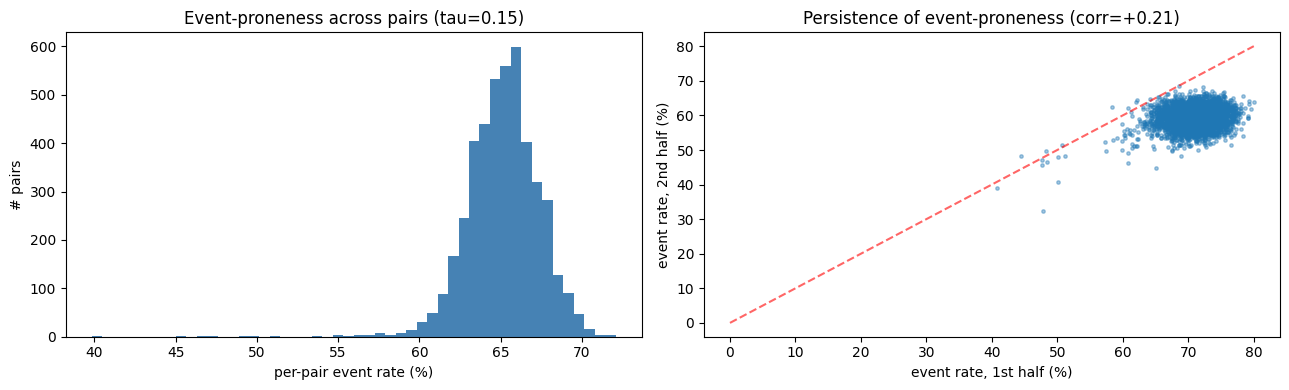

Saved magnitude_event_structure.png


In [6]:
# Cell 6 - Do events concentrate on specific pairs? (learnable structure in WHERE)

TAU_EVENT = 0.15      # 'meaningful shift' threshold for this analysis
event = (np.abs(future_delta) > TAU_EVENT)         # (n_t, N_PAIRS) bool
pair_event_rate = event.mean(axis=0)               # per-pair frequency of events

print(f'Event threshold tau={TAU_EVENT}, overall event rate={event.mean()*100:.1f}%')
print(f'Per-pair event rate: min={pair_event_rate.min()*100:.1f}%  '
      f'median={np.median(pair_event_rate)*100:.1f}%  max={pair_event_rate.max()*100:.1f}%')

# Concentration: do top 10% of pairs account for a disproportionate share of events?
order = np.argsort(pair_event_rate)[::-1]
top10 = order[:int(0.10*N_PAIRS)]
share = event[:, top10].sum() / event.sum()
print(f'Top 10% most event-prone pairs account for {share*100:.1f}% of all events.')

# Persistence: is being event-prone stable over time? Split timeline in half, correlate per-pair rates.
half = len(future_delta)//2
r1 = event[:half].mean(0); r2 = event[half:].mean(0)
persist = np.corrcoef(r1, r2)[0,1]
print(f'Event-proneness persistence (corr of per-pair rate, 1st vs 2nd half): {persist:+.3f}')
print('  (high -> the SAME pairs stay event-prone -> learnable structure in where events occur)')

# Name the most event-prone pairs
print('\nMost event-prone pairs:')
for k in order[:8]:
    a, b = ordered_tickers[iu[k]], ordered_tickers[ju[k]]
    print(f'  {a:>12} <-> {b:<12}  event rate {pair_event_rate[k]*100:.1f}%')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(pair_event_rate*100, bins=50, color='steelblue')
ax[0].set_xlabel('per-pair event rate (%)'); ax[0].set_ylabel('# pairs')
ax[0].set_title(f'Event-proneness across pairs (tau={TAU_EVENT})')
ax[1].scatter(r1*100, r2*100, s=6, alpha=0.4)
ax[1].plot([0, r1.max()*100],[0, r1.max()*100],'r--', alpha=0.6)
ax[1].set_xlabel('event rate, 1st half (%)'); ax[1].set_ylabel('event rate, 2nd half (%)')
ax[1].set_title(f'Persistence of event-proneness (corr={persist:+.2f})')
plt.tight_layout()
plt.savefig(os.path.join(PLOTS, 'magnitude_event_structure.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved magnitude_event_structure.png')


In [ ]:
# Cell 7 - Verdict (refined after the selective-prediction follow-up)

base = mag_df.iloc[0]['best']                       # predictability, all cells
big  = mag_df[mag_df['tau']>=0.15]['best'].mean()   # predictability, big moves

print('VERDICT')
print('='*64)
print(f'Best directional accuracy, ALL cells (tau=0)      : {base:.4f}')
print(f'Best directional accuracy, BIG moves (tau>=0.15)   : {big:.4f}')
print(f'Change                                             : {(big-base)*100:+.1f}pp')
print()
print('--> Predictability RISES sharply with change magnitude.')
print('    Driver = LEVEL mean-reversion (coupling reverts to its 20-day normal);')
print('    the one-line rule alone ~matches the ConvLSTM at tau=0 (0.734).')
print()
print('IMPORTANT - refined conclusion (do NOT build a sparse model):')
print('  * Events are NOT sparse (mean |chg| at H=5 = 0.28; 65% of cells move >0.15)')
print('  * Events do NOT concentrate on specific pairs (top-10% hold ~10.5%,')
print('    persistence +0.21) -> no stable watchlist to learn.')
print('  -> So this is NOT sparse event-detection. It is MAGNITUDE / CONFIDENCE-')
print('     conditioned prediction.')
print()
print('  Follow-up on the existing Trial 7 model (no new model) confirmed:')
print('  conditioning on PREDICTED magnitude (available at inference) yields')
print('  dir-acc 0.844 @54% coverage, 0.872 @42%, 0.918 @23.5%; corr(pred,true')
print('  magnitude)=0.47 -> the model already KNOWS when it is confident.')
print('  => Trial 8 = selective-prediction evaluation of the existing model,')
print('     NOT a new sparse architecture.')